# Practical Session 1 — Python for Data Exploration and Preprocessing
**Machine Learning – 1st year Master – 2026/2027**

Exercises: (1) tabular data & splits, (2) text data, (3) missing values, (4) scaling, binarization and encoding.


In [ ]:
import re
import zlib
import base64
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_20newsgroups, load_iris
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler,
                                   Binarizer, normalize, OrdinalEncoder, LabelEncoder, OneHotEncoder)
from sklearn.utils import Bunch

pd.set_option('display.width', 120)
RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

### Setup — locating the data files (self-contained: copies are embedded)

In [ ]:
DATA_DIR = Path('.')     # your own copies of the files are used if they are in this folder
EMBEDDED = {   # compressed copies of the three provided files (used only if a file is not found)
    'Iris_Dataset.csv': (
        'eNqdV1tuGzEM/M9ZtoYkkpL2CD1FEaRGaiBIAm/QXr9akRtvrOEC7Z+dwfAxHFLOcn5/fPnxcn59/vg1Lf3Ln8vP9vn9/HED9IsC'
        'y/v56XJeHuQUJzrJFE88hVOavl8vy7fl/PG2PD7waW5YcLDSsNQwAlhuWGyYDJi0eNRwFFPa36jljC12aJ/HmGw8AjEZ5uP299Rj'
        'ev1tdUZQS3FiVsuXHWzTLN5hZFgE+erEHUtAlzLxZ3/saEYA28+WhpjUcqrWBHjV8hHIx8ZLgFdgnTq/de7B4ZHFFEfr2fFSgHO4'
        'eSIDXZLpgvyZdj7zPO/NPTq18M6fYy3selAalv7Du8HqRF4S653+KSb3HgLk6fz4YN+3fHQXU9pukoOxe19uMVets+PdGXhwv5ue'
        '57Nzz5Jzs8i9E1onQV6xGXHnWp2/z9fl8vT28nZ9yNY/m09HXGfFffdHXExbtpmN/BVfb052+MVwcfjUe9P684CvdaXeA/WdH/m5'
        '32XNTyB/anix28YADw3ffBAArm+X7g/Sb+Un0wfVF62+4uTX+smpP/fao91tzNf6xNG/9v71NqD6ktXv8df6xPSLjj4rf/V8dfqv'
        'B/6hHt/z341f+h1C/lZ9yYm/6cPOflSLXx28dL70+osz//lAv9X/+cBfYv6ujr4bXhx+3fk7OfWVSexNGfl86J9s7x/bnfT9WRw+'
        '2f1gZz+3+UQHF/NHOMCzxU/QPxo/O/tTjR8gX+8DufdH96PYfSA4/9v9SI4/Zpev++n7W/p+yOfvQf/+xsP7qz7Z5ne5Pl9eL0+P'
        'n/ZS+8z3cDF1pV/peA/r8OdJuvh1hMXYtd+gIbhaQ0/8EFxfBjFnlpGtuXMXDuQunS1f7taOnfpJziYvrDxNqn4YYTbVCKmW7feD'
        'ejeOmm+lBRRc7GJpbka5tTRdPFdzwX3rz3mVJyE4dVlmHFwfQz2WQLXZSiuIratUJx1swLm30gL2WrGHBM579bnmjnjeqa8BZKfd'
        'KwHg7cg4udkmlv3cwayYR5itb2cFZ5sY+1bcciesWrX9FtTYOm/5cj3v3BJsSwgFX98Oze04NXpWzPZfmav5bGzGp6cY7OTe2BFb'
        '8fDs6QInO3t07DXB8Drv5Km2rT/MLTt2QE5VzRk3Nhs7IlEf/gLQrvs1'
    ),
    'txt_file.txt': (
        'eNoz0DM10DHQMwIRFiZAwsBQJ9mQy0DPECQCJkxAhIGRTrIRSNgULgxiGRhDhI2MYIZYGiAZYmQKN9scq9nGFnCzARFqGg8='
    ),
    'employees.csv': (
        '...'
    ),
}
SOURCE = {}

def locate(name):
    p = DATA_DIR / name
    if p.exists():
        SOURCE[name] = 'file found in the notebook folder'
    else:
        p.write_bytes(zlib.decompress(base64.b64decode(''.join(EMBEDDED[name]))))
        SOURCE[name] = 'written from the embedded copy (identical to the provided file)'
    return p

iris_path = locate('Iris_Dataset.csv')
txt_path = locate('txt_file.txt')
emp_path = locate('employees.csv')

for name, src in SOURCE.items():
    print(f"{name:18s} -> {src}")

Iris_Dataset.csv   -> written from the embedded copy (identical to the provided file)
txt_file.txt       -> written from the embedded copy (identical to the provided file)
employees.csv      -> written from the embedded copy (identical to the provided file)


---
# Exercise 1 — Exploring a tabular dataset and creating data splits
### 1. Load the CSV into a DataFrame named `D`

In [3]:
D = pd.read_csv(iris_path)

### 2. Inspect the dataset: `info()`, `describe()`, `shape`, `columns`, `head()`

In [4]:
print("=== D.info() ===")
D.info()
print("\n=== D.describe() ===")
display(D.describe())
print("=== D.shape ===")
print(D.shape)
print("\n=== D.columns ===")
print(D.columns.tolist())
print("\n=== D.head() ===")
display(D.head())

=== D.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

=== D.describe() ===


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


=== D.shape ===
(150, 5)

=== D.columns ===
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

=== D.head() ===


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


**What each output tells us**
- `info()` — index range, number of rows, each column's name, **number of non-null values** (reveals missing data), **dtype** (numeric vs. text/`object`) and memory usage.
- `describe()` — summary statistics of the numeric columns: count, mean, standard deviation, min, quartiles (25 %, 50 % = median, 75 %) and max. It shows the scale and spread of each feature and hints at outliers; text columns are excluded by default.
- `shape` — a tuple `(number of observations, number of columns)`.
- `columns` — the column names (features, label, and possibly an identifier column).
- `head()` — the first 5 rows: a quick visual check that the file was parsed correctly (separators, headers, value formats).

In [5]:
# Identify the roles of the columns automatically (the class label is the only non-numeric column)
target_col = D.select_dtypes(exclude='number').columns[0]
feature_cols = [c for c in D.select_dtypes(include='number').columns if c.lower() not in ('id', 'index')]
print("Target (class label):", target_col)
print("Input features      :", feature_cols)

Target (class label): species
Input features      : ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']


### 3. Select `sepal_length` and `petal_width` and store them in a new DataFrame

In [6]:
two_features = D[['sepal_length', 'petal_width']]
two_features.shape

(150, 2)

### 4. Display the first 20 observations

In [7]:
two_features.head(20)

,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


### 5. Create a copy of the original DataFrame

In [8]:
D_copy = D.copy()                        # independent (deep) copy: data are duplicated

# Demonstration: modifying the copy does not touch the original
D_copy.loc[0, 'sepal_length'] = -999
print("Original  D.loc[0,'sepal_length']     =", D.loc[0, 'sepal_length'])
print("Copy      D_copy.loc[0,'sepal_length'] =", D_copy.loc[0, 'sepal_length'])
print("Same object?", D_copy is D)

Original  D.loc[0,'sepal_length']     = 5.1
Copy      D_copy.loc[0,'sepal_length'] = -999.0
Same object? False


**Why a copy is useful.** Preprocessing experiments (scaling, imputing, dropping or encoding columns) often modify the data *in place*. Working on `D.copy()` keeps the original data intact, so we can compare before/after, undo a mistake, or try several preprocessing alternatives from the same starting point. Note that `D2 = D` would **not** copy: both names would refer to the same object, and changing one would change the other.

### 6–7. Train/test split (80 % / 20 %, `random_state=42`, `stratify=y`)
The dataset has a class label (categorical), so we stratify on it: each split keeps the same class proportions as the full dataset.

- **Input features (X):** all numeric measurement columns (listed above).
- **Target (y):** the class label column.

In [9]:
X = D[feature_cols]
y = D[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

### 8. Verify the number and proportion of observations

In [10]:
n = len(D)
print(f"Total       : {n}")
print(f"Training set: {len(X_train)} observations ({len(X_train)/n:.1%})")
print(f"Test set    : {len(X_test)} observations ({len(X_test)/n:.1%})")
assert len(X_train) + len(X_test) == n and len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert set(X_train.index).isdisjoint(X_test.index)           # no observation in both sets

class_props = pd.DataFrame({
    'Full dataset': y.value_counts(normalize=True),
    'Training':     y_train.value_counts(normalize=True),
    'Test':         y_test.value_counts(normalize=True),
})
counts = pd.DataFrame({'Full dataset': y.value_counts(), 'Training': y_train.value_counts(), 'Test': y_test.value_counts()})
print("\nClass counts:");      display(counts)
print("Class proportions:");   display(class_props.round(3))

Total       : 150
Training set: 120 observations (80.0%)
Test set    : 30 observations (20.0%)

Class counts:


,Full dataset,Training,Test
species,,,
Iris-setosa,50,40,10
Iris-versicolor,50,40,10
Iris-virginica,50,40,10


Class proportions:


,Full dataset,Training,Test
species,,,
Iris-setosa,0.333,0.333,0.333
Iris-versicolor,0.333,0.333,0.333
Iris-virginica,0.333,0.333,0.333


**Discussion — why keep the test set separate?** The test set plays the role of *unseen future data*: it is only meaningful if the model and every preprocessing step have never "seen" it. If test information influences preprocessing (e.g. computing the mean/std for scaling or the imputation values on the full dataset) or model selection (choosing hyperparameters or features by looking at test performance), **information leaks** from the test set into the training procedure (*data leakage*). The consequence is an **optimistically biased** performance estimate that will not hold on genuinely new data, and an overfitted model selection. Hence: split first, fit all preprocessing on the training data only, use the test set once for the final evaluation (and use cross-validation on the training data for model selection).

---
# Exercise 2 — Exploring text data
### 1–2. Open `txt_file.txt` (UTF-8) and display each line without its trailing newline

In [11]:
def open_text(path):
    try:
        f = open(path, 'r', encoding='utf-8')
        f.read(); f.seek(0)
        return f
    except UnicodeDecodeError:
        print("File is not valid UTF-8; falling back to latin-1.")
        return open(path, 'r', encoding='latin-1')

with open_text(txt_path) as f:
    lines = []
    for i, line in enumerate(f, start=1):
        line = line.rstrip('\n')            # remove ONLY the trailing newline (keep spaces, accents, etc.)
        lines.append(line)
        print(f"{i:>3}: {line}")

print("\nNumber of lines:", len(lines))
print("repr of the first lines (shows that only '\\n' was removed):", [repr(l) for l in lines[:3]])

  1: 0.50,0.20,0.84,0.01,c1
  2: 0.10,0.10,0.40,0.02,c2
  3: 0.15,0.10,0.45,0.03,c2
  4: 0.22,0.20,0.90,0.01,c1
  5: 0.25,0.20,0.87,0.01,c1
  6: 0.10,0.10,0.38,0.02,c2

Number of lines: 6
repr of the first lines (shows that only '\n' was removed): ["'0.50,0.20,0.84,0.01,c1'", "'0.10,0.10,0.40,0.02,c2'", "'0.15,0.10,0.45,0.03,c2'"]


**Optional extra — structure of the file.** If the lines are comma-separated records (as in the provided file: four numeric values followed by a class label), pandas can parse them into columns. Reading line by line, as above, is what the exercise requires; the table below only shows how the same lines look once parsed.

In [12]:
if all(',' in l for l in lines if l.strip()):
    txt_df = pd.read_csv(txt_path, header=None, encoding='utf-8')
    txt_df.columns = [f'value_{i+1}' for i in range(txt_df.shape[1] - 1)] + ['label']
    print("Parsed shape:", txt_df.shape)
    display(txt_df)
    print(txt_df.dtypes.to_string())
else:
    print("The lines are free text, not comma-separated records.")

Parsed shape: (6, 5)


,value_1,value_2,value_3,value_4,label
0,0.50,0.2,0.84,0.01,c1
1,0.10,0.1,0.40,0.02,c2
2,0.15,0.1,0.45,0.03,c2
3,0.22,0.2,0.90,0.01,c1
4,0.25,0.2,0.87,0.01,c1
5,0.10,0.1,0.38,0.02,c2


value_1    float64
value_2    float64
value_3    float64
value_4    float64
label          str


### 3. Load the 20 Newsgroups training subset
`fetch_20newsgroups()` downloads the data on first use (internet required). If the download is impossible, a tiny **stand-in** corpus is used so the cells below still run — with internet access you will get the real dataset.

In [13]:
try:
    newsgroups = fetch_20newsgroups(subset='train')          # default categories = all 20 classes
    NEWS_STANDIN = False
except Exception as e:
    print(f"Could not load 20 Newsgroups ({type(e).__name__}); using a tiny STAND-IN corpus instead.")
    NEWS_STANDIN = True
    docs = [
        "The new car has a powerful engine and great fuel economy.",
        "I bought a used car; the engine needs a new clutch.",
        "The team won the hockey game in overtime with a late goal.",
        "Great hockey season: the goalie made forty saves tonight.",
        "NASA announced the launch date of the next space shuttle mission.",
        "The orbit of the satellite was adjusted by the space agency.",
    ]
    newsgroups = Bunch(data=docs, target=np.array([0, 0, 1, 1, 2, 2]),
                       target_names=['rec.autos', 'rec.sport.hockey', 'sci.space'])
print("Using stand-in corpus:", NEWS_STANDIN)

/usr/local/lib/python3.12/dist-packages/sklearn/datasets/_base.py:1519: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5975967
  warnings.warn(f"Retry downloading from url: {remote.url}")


Could not load 20 Newsgroups (URLError); using a tiny STAND-IN corpus instead.
Using stand-in corpus: True


### 4. Number of documents and labels

In [14]:
n_docs = len(newsgroups.data)
n_labels = newsgroups.target.shape[0]
n_classes = len(newsgroups.target_names)
print("Number of documents      :", n_docs)
print("Shape of the target array:", newsgroups.target.shape, "-> one numeric label per document:", n_labels)
print("Number of distinct classes:", n_classes)
assert n_docs == n_labels

Number of documents      : 6
Shape of the target array: (6,) -> one numeric label per document: 6
Number of distinct classes: 3


**Meaning.** `data` is a list of raw text documents; its length is the number of observations (documents). `target` is a 1-D array with **one integer label per document**, so it has the same length as `data`. The number of *distinct* classes (categories/newsgroups) is the length of `target_names`.

### 5. First document and its target label

In [15]:
print(newsgroups.data[0][:600])
print("\n--- target label of document 0:", newsgroups.target[0],
      "->", newsgroups.target_names[newsgroups.target[0]])

The new car has a powerful engine and great fuel economy.

--- target label of document 0: 0 -> rec.autos


### 6. Class names and the numeric ↔ name correspondence

In [16]:
print(newsgroups.target_names)
mapping = dict(enumerate(newsgroups.target_names))
display(pd.Series(mapping, name='class name').rename_axis('numeric target'))
print("Documents per class (first rows):")
display(pd.Series(newsgroups.target).map(mapping).value_counts().head(10))

['rec.autos', 'rec.sport.hockey', 'sci.space']


numeric target
0           rec.autos
1    rec.sport.hockey
2           sci.space
Name: class name, dtype: str

Documents per class (first rows):


rec.autos           2
rec.sport.hockey    2
sci.space           2
Name: count, dtype: int64

**Correspondence.** The numeric value `t = target[i]` is simply the **index into `target_names`**: the class name of document *i* is `target_names[target[i]]`. The integers are arbitrary codes (here following the alphabetical order of the class names), not scores.

### 7. (Optional) Document lengths and frequent words

,count,mean,std,min,25%,50%,75%,max
words per document,6.0,10.8,1.0,9.0,11.0,11.0,11.0,12.0


,word,count
0,new,2
1,car,2
2,engine,2
3,great,2
4,hockey,2
5,space,2
6,powerful,1
7,fuel,1
8,economy,1
9,bought,1


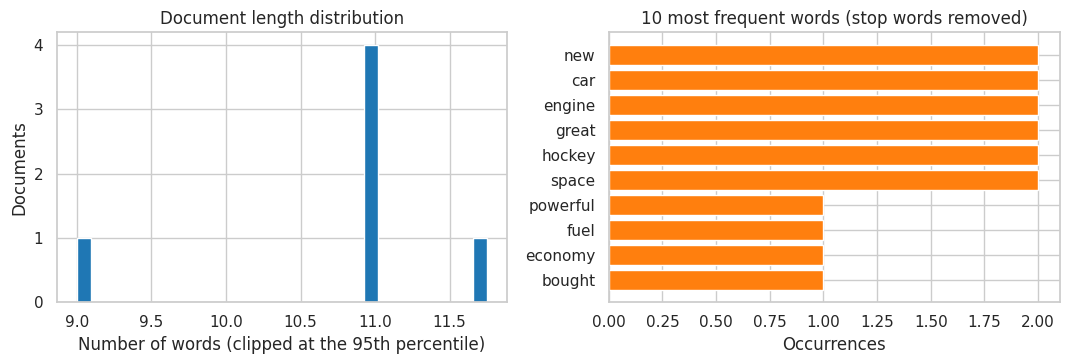

In [17]:
lengths = pd.Series([len(d.split()) for d in newsgroups.data], name='words per document')
display(lengths.describe().round(1).to_frame().T)

tokens = Counter()
for d in newsgroups.data:
    tokens.update(w for w in re.findall(r"\b[a-z]{3,}\b", d.lower()) if w not in ENGLISH_STOP_WORDS)
top = pd.DataFrame(tokens.most_common(10), columns=['word', 'count'])
display(top)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(lengths.clip(upper=lengths.quantile(.95)), bins=30, color='tab:blue')
ax[0].set_xlabel('Number of words (clipped at the 95th percentile)'); ax[0].set_ylabel('Documents')
ax[0].set_title('Document length distribution')
ax[1].barh(top['word'][::-1], top['count'][::-1], color='tab:orange')
ax[1].set_xlabel('Occurrences'); ax[1].set_title('10 most frequent words (stop words removed)')
plt.tight_layout(); plt.show()

---
# Exercise 3 — Detecting and handling missing values
### 1. Load `employees.csv` and inspect it

In [18]:
emp = pd.read_csv(emp_path)
emp.info()
print("\nColumns:", emp.columns.tolist())
display(emp.head())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    str    
 1   Gender             855 non-null    str    
 2   Start Date         1000 non-null   str    
 3   Last Login Time    1000 non-null   str    
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    str    
dtypes: float64(1), int64(1), object(1), str(5)
memory usage: 62.6+ KB

Columns: ['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Salary', 'Bonus %', 'Senior Management', 'Team']


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


### 2. Count missing values per column

In [19]:
missing_original = emp.isna().sum()
missing_original

First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64

### 3. Missing-value pattern (seaborn heatmap)

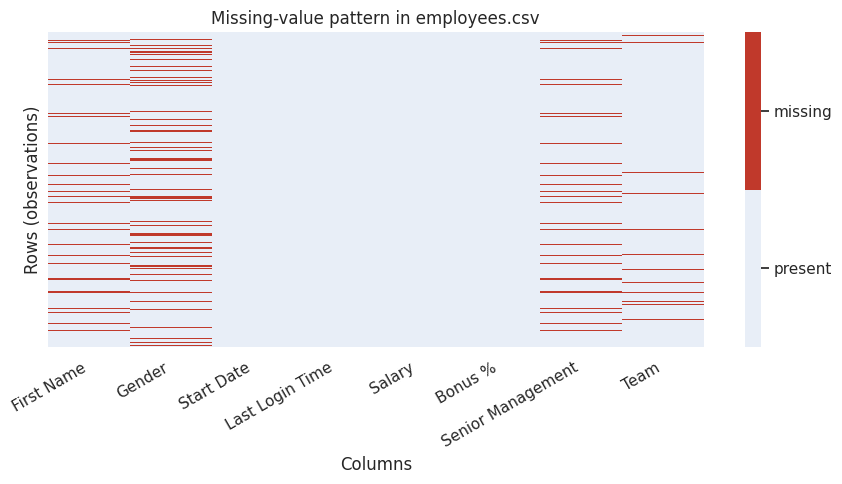

In [20]:
plt.figure(figsize=(9, 5))
ax = sns.heatmap(emp.isna(), cmap=sns.color_palette(['#e8eef7', '#c0392b']), vmin=0, vmax=1,
                 yticklabels=False, cbar_kws={'ticks': [0.25, 0.75]})
ax.collections[0].colorbar.set_ticklabels(['present', 'missing'])
ax.set_title('Missing-value pattern in employees.csv')
ax.set_xlabel('Columns'); ax.set_ylabel('Rows (observations)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

In [21]:
# Do the gaps of different columns occur on the same rows?
n_first, n_senior = emp['First Name'].isna().sum(), emp['Senior Management'].isna().sum()
n_both = (emp['First Name'].isna() & emp['Senior Management'].isna()).sum()
print(f"First Name missing: {n_first} | Senior Management missing: {n_senior} | both missing on the same row: {n_both}")
print("Rows with at least one missing value:", emp.isna().any(axis=1).sum(), "out of", len(emp))

First Name missing: 67 | Senior Management missing: 67 | both missing on the same row: 67
Rows with at least one missing value: 236 out of 1000


**Observation.** Only four columns contain missing values (`First Name`, `Gender`, `Senior Management`, `Team`); `Gender` has the most. `First Name` and `Senior Management` are missing on exactly the same rows (the counts above coincide), so the missingness is not independent from one column to another — it looks structured (probably the same records are incomplete in the source), which matters for the choice of imputation method. The other four columns are complete.

### 4. Copy the DataFrame and append a synthetic row with eight fields
First name = `'-'`, gender = `'na'`; the six other fields get `np.nan` (the standard missing marker, valid for text, numeric and boolean columns alike).

In [22]:
FIRST_COL, GENDER_COL = 'First Name', 'Gender'
assert emp.shape[1] == 8 and FIRST_COL in emp.columns and GENDER_COL in emp.columns, \
    "Adjust FIRST_COL / GENDER_COL to the column names of your employees.csv"

emp_marked = emp.copy()
new_row = {c: np.nan for c in emp.columns}          # one value per column = eight fields
new_row[FIRST_COL] = '-'
new_row[GENDER_COL] = 'na'
emp_marked.loc[len(emp_marked)] = new_row           # append at the end
display(emp_marked.tail(3))
print("Shape before/after:", emp.shape, "->", emp_marked.shape)

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
998,Larry,Male,4/20/2013,4:45 PM,60500.0,11.985,False,Business Development
999,Albert,Male,5/15/2012,6:24 PM,129949.0,10.169,True,Sales
1000,-,na,NaN,NaN,NaN,NaN,NaN,NaN


Shape before/after: (1000, 8) -> (1001, 8)


### 5. Recount the missing values

In [23]:
missing_marked = emp_marked.isna().sum()
cmp5 = pd.DataFrame({'original': missing_original, 'with synthetic row': missing_marked})
cmp5['change'] = cmp5['with synthetic row'] - cmp5['original']
display(cmp5)
print("Occurrences of the placeholders:")
print("  '-'  in", FIRST_COL, ":", (emp_marked[FIRST_COL] == '-').sum())
print("  'na' in", GENDER_COL, ":", (emp_marked[GENDER_COL] == 'na').sum(), "(not counted as missing above)")

,original,with synthetic row,change
First Name,67,67,0
Gender,145,145,0
Start Date,0,1,1
Last Login Time,0,1,1
Salary,0,1,1
Bonus %,0,1,1
Senior Management,67,68,1
Team,43,44,1


Occurrences of the placeholders:
  '-'  in First Name : 1
  'na' in Gender : 1 (not counted as missing above)


**Why `'-'` and `'na'` are not treated as missing.** pandas only treats a few *specific* values as missing: `np.nan`/`None`/`pd.NaT`/`pd.NA`. `'-'` and `'na'` are ordinary non-empty strings, so `isna()` counts them as valid values: First Name and Gender did not change, only the six `np.nan` fields did. (`read_csv` additionally converts a default list of strings such as `''`, `'NA'`, `'N/A'`, `'NaN'`, `'null'` when *reading a file*, but neither `'-'` nor lowercase `'na'` is in that list, and our row was added to an already-loaded DataFrame anyway.) Such placeholders must therefore be converted explicitly.

### 6. Convert the markers to `np.nan` — documented, case-consistent rule
**Rule:** in every text column, a value is considered missing if, after removing surrounding whitespace and converting to lowercase, it belongs to `MISSING_MARKERS`. This makes `'NA'`, `'Na'`, `' na '` and `'na'` equivalent. Non-text columns are left untouched.

In [24]:
MISSING_MARKERS = {'-', 'na', 'n/a', 'null', 'none', 'nan', ''}      # agreed placeholders (compared in lowercase)

def markers_to_nan(frame, markers=MISSING_MARKERS):
    out = frame.copy()
    for col in out.columns:
        s = out[col]
        if s.dtype == object or pd.api.types.is_string_dtype(s):
            is_marker = s.astype('string').str.strip().str.lower().isin(markers).fillna(False).to_numpy(dtype=bool)
            out[col] = s.mask(is_marker, np.nan)
    return out

emp_clean = markers_to_nan(emp_marked)
cmp6 = pd.DataFrame({'before conversion': emp_marked.isna().sum(), 'after conversion': emp_clean.isna().sum()})
display(cmp6)
assert emp_clean.loc[emp_clean.index[-1], [FIRST_COL, GENDER_COL]].isna().all()

,before conversion,after conversion
First Name,67,68
Gender,145,146
Start Date,1,1
Last Login Time,1,1
Salary,1,1
Bonus %,1,1
Senior Management,68,68
Team,44,44


### 7. Imputation with `SimpleImputer`
Imputers are **fitted on the training part only** and then applied to the test part (no leakage). Choices per column:
- **Numerical** (`Salary`, `Bonus %`) → `median` (robust to outliers).
- **Categorical** (`Gender`, `Senior Management`, `Team`, and the text-coded `Start Date` / `Last Login Time`) → `most_frequent`.
- **`First Name` is an identifier-like field → not imputed.** Replacing a missing name by the most frequent name would invent a false identity and carry no information; it is left as missing (or the row is dropped if the name is needed).

In [25]:
num_cols = emp_clean.select_dtypes(include='number').columns.tolist()
id_cols = [FIRST_COL]
cat_cols = [c for c in emp_clean.columns if c not in num_cols + id_cols]
print("Numerical  :", num_cols)
print("Categorical:", cat_cols)
print("Identifier (not imputed):", id_cols)

emp_train, emp_test = train_test_split(emp_clean, test_size=0.2, random_state=RANDOM_STATE)

imputer = ColumnTransformer(
    [('cat', SimpleImputer(strategy='most_frequent'), cat_cols),
     ('num', SimpleImputer(strategy='median'), num_cols)],
    remainder='passthrough', verbose_feature_names_out=False)
imputer.set_output(transform='pandas')

emp_train_imp = imputer.fit_transform(emp_train)[emp_clean.columns]     # fit on TRAIN only
emp_test_imp = imputer.transform(emp_test)[emp_clean.columns]           # reuse the fitted statistics

print("\nValues learned on the training set:")
print("  most_frequent:", dict(zip(cat_cols, imputer.named_transformers_['cat'].statistics_)))
print("  median       :", dict(zip(num_cols, imputer.named_transformers_['num'].statistics_)))

Numerical  : ['Salary', 'Bonus %']
Categorical: ['Gender', 'Start Date', 'Last Login Time', 'Senior Management', 'Team']
Identifier (not imputed): ['First Name']

Values learned on the training set:
  most_frequent: {'Gender': 'Male', 'Start Date': '10/23/1995', 'Last Login Time': '12:04 PM', 'Senior Management': True, 'Team': 'Business Development'}
  median       : {'Salary': np.float64(90556.0), 'Bonus %': np.float64(10.012)}


### 8. Missing values before vs. after preprocessing

In [26]:
emp_imputed = pd.concat([emp_train_imp, emp_test_imp]).sort_index()
summary = pd.DataFrame({
    'original file': missing_original,
    '+ synthetic row': missing_marked,
    'after marker -> NaN': emp_clean.isna().sum(),
    'after imputation': emp_imputed.isna().sum(),
})
display(summary)
print("Total missing values:", summary.sum().to_dict())

,original file,+ synthetic row,after marker -> NaN,after imputation
First Name,67,67,68,68
Gender,145,145,146,0
Start Date,0,1,1,0
Last Login Time,0,1,1,0
Salary,0,1,1,0
Bonus %,0,1,1,0
Senior Management,67,68,68,0
Team,43,44,44,0


Total missing values: {'original file': 322, '+ synthetic row': 328, 'after marker -> NaN': 330, 'after imputation': 68}


**Limitations of imputation.**
- Imputed values are **guesses**, not observations: they add no real information and hide the uncertainty (a filled value looks as reliable as a measured one).
- Median/mode imputation **shrinks the variance** and distorts distributions, correlations and category frequencies (the majority class gets over-represented).
- It implicitly assumes values are missing *completely at random* (or at random given other variables); if the missingness itself is informative (e.g. missing because of the value), the result is biased. A "missing" indicator (`add_indicator=True`) can preserve that signal.
- Rows containing placeholders in many fields (like our synthetic row, where almost everything is unknown) are better removed than imputed field by field. In particular, filling the synthetic row's `Start Date` and `Last Login Time` with the most frequent value fabricates a date/time: this is done here only to follow the exercise (categorical → `most_frequent`).
- Identifiers should not be imputed; more advanced methods (KNN / iterative / multiple imputation) can exploit relations between columns but are costlier and still rely on assumptions.

---
# Exercise 4 — Feature scaling, binarization and categorical encoding
## Part A. Scaling and binarization
### 1–2. Apply the five methods and display the results

In [27]:
X_num = np.array([[1., -1.,  2.],
                  [2.,  0.,  0.],
                  [0.,  1., -1.]])
cols = ['Feature 1', 'Feature 2', 'Feature 3']
show = lambda arr: pd.DataFrame(arr, columns=cols, index=['row 1', 'row 2', 'row 3']).round(4)

results = {
    'StandardScaler (per feature)': StandardScaler().fit_transform(X_num),
    'MinMaxScaler (per feature)':   MinMaxScaler().fit_transform(X_num),
    'MaxAbsScaler (per feature)':   MaxAbsScaler().fit_transform(X_num),
    'RobustScaler (per feature)':   RobustScaler().fit_transform(X_num),
    'normalize, L2 (per sample)':   normalize(X_num, norm='l2', axis=1),
}
print("Original matrix:"); display(show(X_num))
for name, arr in results.items():
    print(name); display(show(arr))

Original matrix:


,Feature 1,Feature 2,Feature 3
row 1,1.0,-1.0,2.0
row 2,2.0,0.0,0.0
row 3,0.0,1.0,-1.0


StandardScaler (per feature)


,Feature 1,Feature 2,Feature 3
row 1,0.0000,-1.2247,1.3363
row 2,1.2247,0.0000,-0.2673
row 3,-1.2247,1.2247,-1.0690


MinMaxScaler (per feature)


,Feature 1,Feature 2,Feature 3
row 1,0.5,0.0,1.0000
row 2,1.0,0.5,0.3333
row 3,0.0,1.0,0.0000


... (2 outputs left out)

RobustScaler (per feature)


,Feature 1,Feature 2,Feature 3
row 1,0.0,-1.0,1.3333
row 2,1.0,0.0,0.0000
row 3,-1.0,1.0,-0.6667


normalize, L2 (per sample)


,Feature 1,Feature 2,Feature 3
row 1,0.4082,-0.4082,0.8165
row 2,1.0000,0.0000,0.0000
row 3,0.0000,0.7071,-0.7071


In [28]:
# Sanity checks of the defining property of each method
S, MM, MA, R, N = results.values()
assert np.allclose(S.mean(axis=0), 0) and np.allclose(S.std(axis=0), 1)               # mean 0, std 1 per column
assert np.allclose(MM.min(axis=0), 0) and np.allclose(MM.max(axis=0), 1)              # range [0, 1] per column
assert np.allclose(np.abs(MA).max(axis=0), 1)                                         # max |value| = 1 per column
assert np.allclose(np.median(R, axis=0), 0)                                           # median 0 per column
assert np.allclose(np.linalg.norm(N, axis=1), 1)                                      # unit L2 norm per ROW
print("All sanity checks passed.")

All sanity checks passed.


### 3. Main idea of each method
| Method | Idea (formula) | Acts on |
|---|---|---|
| `StandardScaler` | $z=(x-\mu)/\sigma$ → mean 0, standard deviation 1 (population std, `ddof=0`) | each **feature** (column) |
| `MinMaxScaler` | $(x-x_{min})/(x_{max}-x_{min})$ → range $[0,1]$ | each **feature** |
| `MaxAbsScaler` | $x/\max\lvert x\rvert$ → range $[-1,1]$; no shifting, so zeros and sparsity are preserved | each **feature** |
| `RobustScaler` | $(x-\text{median})/\text{IQR}$ (IQR = Q3 − Q1) → little influence from outliers | each **feature** |
| `normalize` | $x/\lVert x\rVert_2$ → each row has unit L2 norm (`norm='l1'`/`'max'` also available) | each **sample** (row) |

The first four are *feature scalers* (statistics computed per column over all samples; they are fitted on training data and reused on test data); `normalize` is a *sample normalizer* (each row is rescaled independently, nothing is learned).

### 4. Binarization with explicit thresholds
`Binarizer(threshold=t)` outputs 1 if `x > t` (strictly greater) and 0 otherwise.

In [29]:
for t in (0.0, 1.0):
    print(f"Threshold = {t}  (value > {t} -> 1, otherwise 0)")
    display(show(Binarizer(threshold=t).fit_transform(X_num)))

Threshold = 0.0  (value > 0.0 -> 1, otherwise 0)


,Feature 1,Feature 2,Feature 3
row 1,1.0,0.0,1.0
row 2,1.0,0.0,0.0
row 3,0.0,1.0,0.0


Threshold = 1.0  (value > 1.0 -> 1, otherwise 0)


,Feature 1,Feature 2,Feature 3
row 1,0.0,0.0,1.0
row 2,1.0,0.0,0.0
row 3,0.0,0.0,0.0


**Effect of the threshold.** With `threshold=0`, every strictly positive value becomes 1 (zeros and negatives become 0). Raising it to `1` turns the values equal to 1 into 0 as well, so fewer entries are 1: the higher the threshold, the sparser the binary matrix. The threshold decides which values are considered "present/high"; all information about the magnitude is discarded.

**Discussion — does scaling matter?**
- **k-NN and SVM** rely on distances/dot products: a feature with a large range (e.g. salary in thousands vs. age) dominates the distance and the kernel, so features must be put on comparable scales.
- **Gradient-based models** (linear/logistic regression, neural networks): different feature scales produce an ill-conditioned loss surface, which slows or destabilizes gradient descent; scaling speeds up convergence and makes regularization (L1/L2) treat all features fairly.
- **Decision trees (and random forests)**: scaling is *not necessary*, because a split only compares a feature with a threshold and is invariant to monotonic transformations of that feature.

## Part B. Encoding categorical variables

In [30]:
cat_df = pd.DataFrame({
    'Feature 1': ['male', 'female', 'female', 'male'],
    'Feature 2': ['from US', 'from Europe', 'from Asia', 'from Africa'],
    'Feature 3': ['uses Safari', 'uses Safari', 'uses Firefox', 'uses Chrome'],
    'Target':    ['US', 'France', 'Japan', 'Algeria'],
})
cat_df

,Feature 1,Feature 2,Feature 3,Target
0,male,from US,uses Safari,US
1,female,from Europe,uses Safari,France
2,female,from Asia,uses Firefox,Japan
3,male,from Africa,uses Chrome,Algeria


### 1. `OrdinalEncoder` on the three input features

In [31]:
X_cat = cat_df[['Feature 1', 'Feature 2', 'Feature 3']]
ord_enc = OrdinalEncoder()
X_ord = ord_enc.fit_transform(X_cat)

display(pd.DataFrame(X_ord, columns=X_cat.columns).astype(int))
for col, cats in zip(X_cat.columns, ord_enc.categories_):
    print(f"{col}: {dict(zip(cats, range(len(cats))))}")
print("\ncategories_ =", ord_enc.categories_)

,Feature 1,Feature 2,Feature 3
0,1,3,2
1,0,2,2
2,0,1,1
3,1,0,0


Feature 1: {'female': 0, 'male': 1}
Feature 2: {'from Africa': 0, 'from Asia': 1, 'from Europe': 2, 'from US': 3}
Feature 3: {'uses Chrome': 0, 'uses Firefox': 1, 'uses Safari': 2}

categories_ = [array(['female', 'male'], dtype=object), array(['from Africa', 'from Asia', 'from Europe', 'from US'], dtype=object), array(['uses Chrome', 'uses Firefox', 'uses Safari'], dtype=object)]


`categories_` lists, for each feature, the sorted categories; the integer assigned to a category is its **position in that list** (alphabetical order by default). These numbers are just **category codes**: e.g. `male = 1 > female = 0` or `from US = 3 > from Africa = 0` do not mean anything about the real world. A model that treats them as numbers would wrongly assume an order and distances between the categories.

### 2. Encode the target separately (`LabelEncoder`)

In [32]:
label_enc = LabelEncoder()
y_enc = label_enc.fit_transform(cat_df['Target'])
print("Encoded target:", y_enc)
print("Mapping       :", {cls: int(i) for i, cls in enumerate(label_enc.classes_)})
print("Inverse check :", label_enc.inverse_transform(y_enc).tolist())

# Equivalent with OrdinalEncoder (expects a 2-D array)
print("OrdinalEncoder gives the same codes:",
      np.array_equal(OrdinalEncoder().fit_transform(cat_df[['Target']]).ravel().astype(int), y_enc))

Encoded target: [3 1 2 0]
Mapping       : {'Algeria': 0, 'France': 1, 'Japan': 2, 'US': 3}
Inverse check : ['US', 'France', 'Japan', 'Algeria']
OrdinalEncoder gives the same codes: True


### 3. `OneHotEncoder` on the target

In [33]:
ohe_target = OneHotEncoder(sparse_output=False)
y_onehot = ohe_target.fit_transform(cat_df[['Target']])
print("categories_:", ohe_target.categories_)
display(pd.DataFrame(y_onehot.astype(int), columns=ohe_target.get_feature_names_out(['Target']),
                     index=cat_df['Target'].rename('original label')))

categories_: [array(['Algeria', 'France', 'Japan', 'US'], dtype=object)]


,Target_Algeria,Target_France,Target_Japan,Target_US
original label,,,,
US,0,0,0,1
France,0,1,0,0
Japan,0,0,1,0
Algeria,1,0,0,0


**Integer label encoding vs. one-hot encoding.** Label encoding maps each class to **one integer** (one column: `Algeria=0, France=1, Japan=2, US=3`); it is compact and is what scikit-learn classifiers expect for `y`, but the integers carry an artificial order. One-hot encoding creates **one binary column per class** (exactly one `1` per row); no order is implied and all categories are equidistant, at the cost of more columns.

### 4. Why one-hot is preferable to arbitrary ordinal codes for *nominal* inputs
Gender, region or browser have **no natural order**. Ordinal codes introduce a false ranking and false distances (e.g. Safari = 2 is "twice" Firefox = 1; Africa = 0 is "closer" to Asia = 1 than to US = 3), which distance-based and linear/gradient-based models will exploit incorrectly. One-hot columns let the model learn an independent effect for each category. (Ordinal codes remain appropriate for genuinely *ordered* categories such as small < medium < large, and are harmless for tree-based models.) Drawbacks of one-hot: many columns for high-cardinality features, and handling of categories unseen at training time (`handle_unknown='ignore'`).

In [34]:
# Demonstration: one-hot encoding of the three nominal input features
ohe_X = OneHotEncoder(sparse_output=False)
X_ohe = ohe_X.fit_transform(X_cat)
display(pd.DataFrame(X_ohe.astype(int), columns=ohe_X.get_feature_names_out(X_cat.columns)))

,Feature 1_female,Feature 1_male,Feature 2_from Africa,Feature 2_from Asia,Feature 2_from Europe,Feature 2_from US,Feature 3_uses Chrome,Feature 3_uses Firefox,Feature 3_uses Safari
0,0,1,0,0,0,1,0,0,1
1,1,0,0,0,1,0,0,0,1
2,1,0,0,1,0,0,0,1,0
3,0,1,1,0,0,0,1,0,0


---
# Conclusion — which preprocessing for which type of data?
- **Numerical data:** inspect with `describe()`; handle missing values (median imputation is robust); **scale** features for distance-/gradient-based models (`StandardScaler` by default, `MinMaxScaler` for bounded ranges, `RobustScaler` with outliers, `MaxAbsScaler` for sparse data); `normalize` rescales *samples*; binarization turns values into presence/absence. Tree-based models do not need scaling.
- **Categorical data:** convert non-standard placeholders (`'-'`, `'na'`) to `NaN` with a consistent rule, impute with the most frequent category (not for identifiers), then encode: **one-hot** for nominal features, **ordinal codes** only for ordered categories, and `LabelEncoder` for the target.
- **Text data:** read with the correct encoding (UTF-8), clean line endings, explore size and vocabulary (document lengths, frequent words, class distribution) before converting text to numerical features (e.g. bag-of-words / TF-IDF).
- **Always:** keep the raw data unchanged (work on copies), split into train/test first with a fixed `random_state` (stratified for classification), and **fit every imputer/scaler/encoder on the training set only** (ideally inside a `Pipeline`) to avoid data leakage.